<a href="https://colab.research.google.com/github/mariosolervidal/Proyecto_Tema2/blob/main/Proyecto2_Fase1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **PROYECTO 2, FASE 1:PREDICCIÓN DE ABONDONO ESTUDIANTIL**

Para este proyecto seguiremos **CRISP-DM** (*Cross-Industry Standard Process for Data Mining*), el estándar de referencia para proyectos de minería de datos y machine learning. Esta metodología ofrece una estructura clara y repetible para llevar un proyecto de datos de principio a fin.

CRISP-DM organiza el trabajo en **seis fases**:

1. **Comprensión del negocio** — Nuestro objetivo es comprender qué variables llevan al desarrollo del abandono en el contexto educativo, para poder predecir qué sujetos se encuentran bajo riesgo. Para esto, es muy importante entender el conjunto de datos sobre el que vamos a desarrollar nuestro análisis.Empezaremos analizando que información aporta cada variable en el siguiente paso.
2. **Comprensión de los datos** — explorar el dataset, entender las variables y su calidad - Exploratory Data Analysis(EDA).
3. **Preparación de los datos** — limpieza, tratamiento de valores atípicos y selección de las variables que alimentarán el modelo - Feature Engineering.
4. **Modelado** — entrenar el modelo (aquí, una regresión lineal) para predecir la variable objetivo `dropout_risk_score`.
5. **Evaluación** — validar el modelo y medir su rendimiento con métricas adecuadas antes de darlo por bueno.
6. **Despliegue** — integrar el modelo en la solución final para que aporte valor.

En este cuaderno desarrollaremos la parte práctica (fases 2 a 5 sobre el dataset de abandono estudiantil), mientras que la fase 6 se abordará a nivel conceptual en el documento, dentro de la arquitectura cloud de la solución.

### Paquetes que utilizamos en el proyecto

In [1]:
# === Manipulación de datos ===
import pandas as pd

# === Visualización ===
import matplotlib.pyplot as plt
import seaborn as sns

# === Utilidades ===
import math
from google.colab import files

# === Modelado (scikit-learn) ===
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

# === Diagnóstico estadístico ===
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant
import scipy.stats as stats

## **Compresión del caso de estudio/negocio**
A continuación vamos a inspeccionar brevemente la fuente de datos que se nos ha facilitado para realizar este análisis, siendo este el dataset: 'student_dropout_risk_dataset_gaussiannoise.csv', además, explicaré brevemente cuál va a ser mi estructura de trabajo para llevar a cabo este análisis.


In [2]:
uploaded = files.upload()

Saving student_dropout_risk_dataset_gaussiannoise (1).csv to student_dropout_risk_dataset_gaussiannoise (1).csv


In [3]:
df=pd.read_csv('/content/student_dropout_risk_dataset_gaussiannoise (1).csv')

In [4]:
print(f"El dataset tiene un tamaño de: {df.shape[0]} observaciones\n")

print(f"EL dataset tiene: {len(df.columns)} variables, que son las siguientes:\n")
df.columns

El dataset tiene un tamaño de: 733 observaciones

EL dataset tiene: 9 variables, que son las siguientes:



Index(['age', 'GPA', 'attendance', 'study_hours', 'assignment_delay',
       'platform_usage', 'working_student', 'scholarship',
       'dropout_risk_score'],
      dtype='object')

- Tras importar el dataset, definimos este con el nombre:'df'. El archivo original era de tipo de *csv* y hemos convertido este a un *dataframe* utilizando la librería pandas.
- 'df' tiene 733 observaciones(estudiantes) y 9 variables: 8 de ellas explicativas y 1 variable respuesta/objetivo que és *dropout_risk_score* que determina el riesgo de abanbono escolar que representa cada sujeto, medido con escala de 0 a 100.
- Nuestro objetivo en este análisis es determinar que variables del dataframe son verdaderamente representativas en cuánto a desarrollo de abandono escolar, y poder utilizar estas para desarrollar un modelo de predicción, que nos ayude a identificar estos casos de riesgo y tratarlos.

## **Exploratory Data Analysis(EDA)**

In [5]:
df.head()

,age,GPA,attendance,study_hours,assignment_delay,platform_usage,working_student,scholarship,dropout_risk_score
0,24,8.26,90.04,36.8,1,36.02,1,0,33.718206
1,37,6.03,81.49,20.8,6,69.34,1,1,42.372571
2,46,6.37,60.82,24.7,2,79.43,1,0,40.706150
3,32,6.07,75.91,6.3,7,79.03,0,1,36.869929
4,28,6.89,79.86,1.7,6,61.72,1,1,46.752730


In [6]:
df.dtypes

,0
age,int64
GPA,float64
attendance,float64
study_hours,float64
assignment_delay,int64
platform_usage,float64
working_student,int64
scholarship,int64
dropout_risk_score,float64


In [7]:
df.describe()

,age,GPA,attendance,study_hours,assignment_delay,platform_usage,working_student,scholarship,dropout_risk_score
count,733.000000,733.000000,733.000000,733.000000,733.000000,733.000000,733.000000,733.000000,733.000000
mean,34.077763,7.549250,74.870941,19.841473,4.495225,59.415948,0.518417,0.478854,34.121845
std,9.770772,1.410934,14.213681,11.717065,2.883729,22.746163,0.500002,0.499894,12.278267
min,18.000000,5.000000,50.020000,0.000000,0.000000,20.050000,0.000000,0.000000,0.000000
25%,25.000000,6.360000,62.300000,9.300000,2.000000,39.320000,0.000000,0.000000,25.307048
50%,35.000000,7.620000,75.310000,20.300000,5.000000,59.030000,1.000000,0.000000,34.233712
75%,43.000000,8.720000,87.290000,29.900000,7.000000,79.380000,1.000000,1.000000,42.863198
max,49.000000,10.000000,99.820000,40.000000,9.000000,99.960000,1.000000,1.000000,66.083272


El número de valores nulos del dataset es: 0



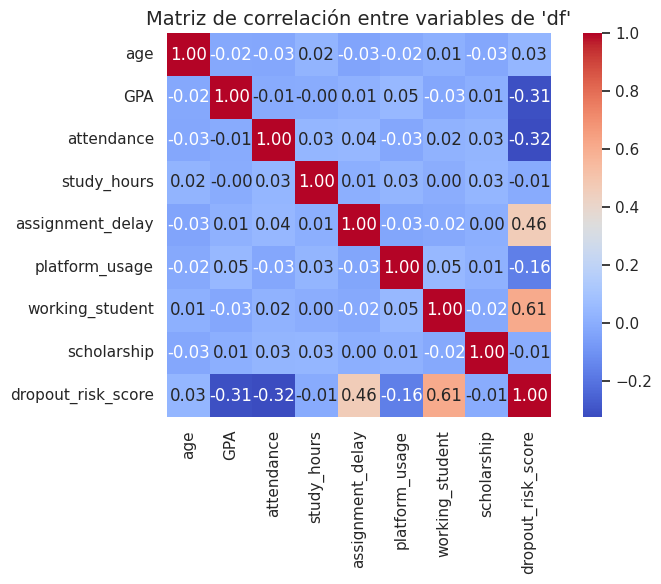

In [8]:
null_values=df.isnull().sum().sum()
print(f"El número de valores nulos del dataset es: {null_values}\n")
corr_matrix = df.corr()

# mapa de calor paquete seaborn; estudio de correlación entre variables
sns.set_theme(style="whitegrid", palette="deep", context="notebook")
plt.figure(figsize=(8, 6))
heatmap = sns.heatmap(
    corr_matrix,
    annot=True,        # Mostrar valores numéricos
    fmt=".2f",         # Formato de los números
    cmap="coolwarm",   # Paleta de colores
    cbar=True,         # Barra de color
    square=True        # Celdas cuadradas
)

plt.title("Matriz de correlación entre variables de 'df'", fontsize=14)
plt.tight_layout()
plt.show()


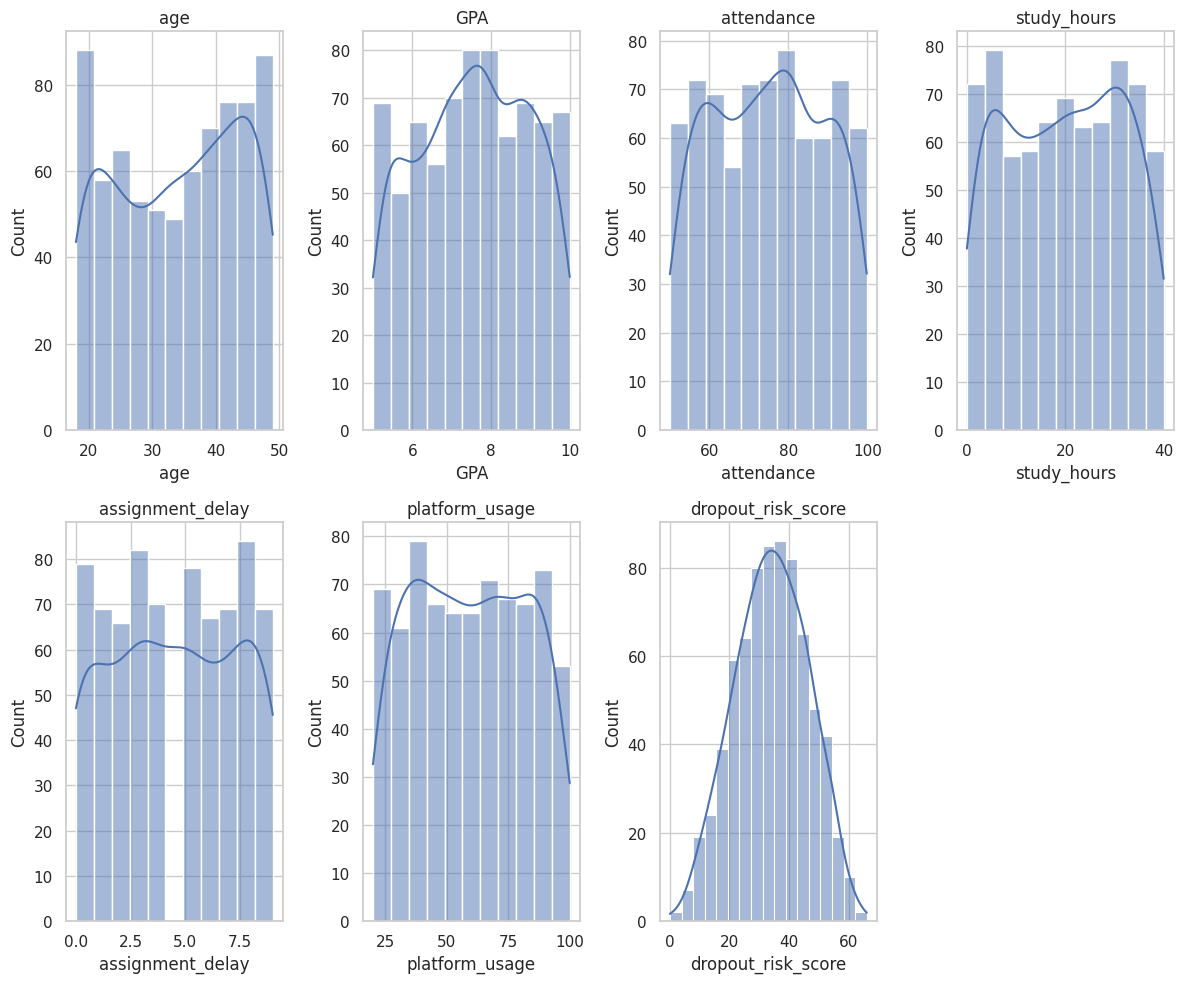

In [9]:
df_continuous_var = df.drop(['working_student', 'scholarship'], axis=1)
columnas = df_continuous_var.columns

# Rejilla dinámica según el nº de variables
ncols = 4
nrows = math.ceil(len(columnas) / ncols)#redondea hacía arriba 'ceiling'

fig, axes = plt.subplots(nrows, ncols, figsize=(12, 5 * nrows))
axes = axes.flatten()

# Un histograma por variable
for i, col in enumerate(columnas):
    sns.histplot(df_continuous_var[col], kde=True, bins='auto', ax=axes[i])
    axes[i].set_title(col)

# Ocultar los subplots sobrantes
for j in range(len(columnas), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

In [10]:
# Solo las predictoras (sin la variable objetivo)
X = add_constant(df.drop(columns=['dropout_risk_score']))

vif_df = pd.DataFrame()
vif_df["Feature"] = X.columns
vif_df["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
print(vif_df)

            Feature       VIF
0             const  1.000000
1               age  1.004444
2               GPA  1.003885
3        attendance  1.005574
4       study_hours  1.004135
5  assignment_delay  1.004041
6    platform_usage  1.007808
7   working_student  1.004034
8       scholarship  1.003141


### Análisis Exploratorio de Datos (EDA)

**Calidad de los datos.** 'df' no contiene valores nulos. El dataframe contiene variables con tipos coherentes: 6 continuas, 2 binarias (`working_student`, `scholarship`) y el target. Rangos plausibles, sin outliers extremos.

**Distribuciones.** El target (`dropout_risk_score`) es aproximadamente **normal** y simétrico. Entre las explicativas: `age` es bimodal (picos en los extremos); `GPA` es débilmente bimodal; `attendance`, `assignment_delay` y `platform_usage` son casi planas con fluctuaciones; `study_hours` es irregular. Las binarias están equilibradas (~52 % trabaja, ~48 % con beca). Ninguna muestra asimetría marcada, así que no se requieren transformaciones por sesgo.

**Correlación con el target.** `working_student` **+0.61** y `assignment_delay` **+0.46** aumentan el riesgo; `attendance` **−0.32** y `GPA` **−0.31** lo reducen; `platform_usage` −0.16 es débil; `age`, `study_hours` y `scholarship` son prácticamente nulas. Los signos son coherentes con la lógica del dominio.

**Implicaciones.** No se detecta multicolinealidad: todos los VIF son ≈ 1 (máximo 1.008, muy por debajo del umbral de 5), lo que garantiza coeficientes estables e interpretables en la regresión lineal. `study_hours` y `scholarship` aportan poco y habrá que vigilarlas. Las correlaciones son moderadas.Las relaciones son aproximadamente lineales, lo que respalda el uso de la **regresión lineal**.

## **Fase de modelado**

### Hipótesis 1- Modelado con las 8 variables explicativas

In [11]:
x=df.drop(columns=['dropout_risk_score'])
y=df['dropout_risk_score']
modelo_rl=LinearRegression()
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)
#fase de entrenamiento
modelo_rl.fit(x_train,y_train)

LinearRegression()

#### Predicción(train & test) H1

In [12]:
y_pred_train=modelo_rl.predict(x_train)
y_pred_test=modelo_rl.predict(x_test)

#####  Validación y métricas H1

In [13]:
mse_train=mean_squared_error(y_train,y_pred_train)
r2_train=r2_score(y_true=y_train,y_pred=y_pred_train)
mae_train=mean_absolute_error(y_true=y_train,y_pred=y_pred_train)
mse_test=mean_squared_error(y_test,y_pred_test)
r2_test=r2_score(y_true=y_test,y_pred=y_pred_test)
mae_test=mean_absolute_error(y_true=y_test,y_pred=y_pred_test)
print("---- TRAIN (H1, 8 variables explicativas) ----")
print(f"El MSE para train es: {mse_train:.4f}")
print(f"El R²  para train es: {r2_train:.4f}")
print(f"El MAE para train es: {mae_train:.4f}")

print("\n---- TEST (H1, 8 variables explicativas) ----")
print(f"El MSE para test es: {mse_test:.4f}")
print(f"El R²  para test es: {r2_test:.4f}")
print(f"El MAE para test es: {mae_test:.4f}")

---- TRAIN (H1, 8 variables explicativas) ----
El MSE para train es: 25.1532
El R²  para train es: 0.8397
El MAE para train es: 3.9798

---- TEST (H1, 8 variables explicativas) ----
El MSE para test es: 20.3390
El R²  para test es: 0.8374
El MAE para test es: 3.5693


### Hipótesis 2- Modelado con 5 variables explicativas(excluimos variables:`age`,`study_hours`,`scholarship`

In [14]:
df_H2=df.drop(columns=['age','study_hours','scholarship'])

In [15]:
df_H2.shape[1]#confirmamos que hemos eliminado efectivamente las 3 variables explicativas con correlación con variable objetivo prácticamente 0

6

In [16]:
x_H2=df_H2.drop(columns=['dropout_risk_score'])
y_H2=df_H2['dropout_risk_score']

In [17]:
x_train_H2,x_test_H2,y_train_H2,y_test_H2=train_test_split(x_H2,y_H2,test_size=0.2,random_state=42)
modelo_rl_H2=LinearRegression()
modelo_rl_H2.fit(x_train_H2,y_train_H2)

LinearRegression()

#### Predicción(train,test) H2

In [18]:
y_pred_train_H2=modelo_rl_H2.predict(x_train_H2)
y_pred_test_H2=modelo_rl_H2.predict(x_test_H2)

##### Validación y métricas H2

In [19]:
mse_train_H2 = mean_squared_error(y_train_H2, y_pred_train_H2)
r2_train_H2  = r2_score(y_true=y_train_H2, y_pred=y_pred_train_H2)
mae_train_H2 = mean_absolute_error(y_true=y_train_H2, y_pred=y_pred_train_H2)

mse_test_H2 = mean_squared_error(y_test_H2, y_pred_test_H2)
r2_test_H2  = r2_score(y_true=y_test_H2, y_pred=y_pred_test_H2)
mae_test_H2 = mean_absolute_error(y_true=y_test_H2, y_pred=y_pred_test_H2)

print("---- TRAIN (H2, 5 variables explicativas) ----")
print(f"El MSE para train es: {mse_train_H2:.4f}")
print(f"El R²  para train es: {r2_train_H2:.4f}")
print(f"El MAE para train es: {mae_train_H2:.4f}")

print("\n---- TEST (H2, 5 variables explicativas) ----")
print(f"El MSE para test es: {mse_test_H2:.4f}")
print(f"El R²  para test es: {r2_test_H2:.4f}")
print(f"El MAE para test es: {mae_test_H2:.4f}")

---- TRAIN (H2, 5 variables explicativas) ----
El MSE para train es: 25.3318
El R²  para train es: 0.8386
El MAE para train es: 3.9950

---- TEST (H2, 5 variables explicativas) ----
El MSE para test es: 20.1834
El R²  para test es: 0.8386
El MAE para test es: 3.5789


## **Fase de evaluación**

### Selección del modelo ganador

Ambos modelos ofrecen un rendimiento prácticamente idéntico, pero el modelo reducido lo logra con tres variables menos (`age`, `study_hours`, `scholarship`), confirmando que no son necesarias. Por el **principio de parsimonia** se selecciona el *modelo reducido de 5 variables*, **H2**, como modelo final: igual capacidad predictiva, mayor simplicidad e idéntica (incluso ligeramente mejor) capacidad de generalización.

#### Interpretación de coeficientes del modelo **H2**

In [20]:
coef_df = pd.DataFrame({
    "Variable": x_H2.columns,
    "Coeficiente": modelo_rl_H2.coef_
}).sort_values("Coeficiente", ascending=False)

print(f"Intercepto (β0): {modelo_rl_H2.intercept_:.4f}\n")
print(coef_df)

Intercepto (β0): 65.8496

           Variable  Coeficiente
4   working_student    15.495068
2  assignment_delay     2.073757
3    platform_usage    -0.090859
1        attendance    -0.318674
0               GPA    -2.619210


El modelo de predicción queda definido por la siguiente función:

dropout_risk_score_pred = 65.8496
                        + 15.4951 · working_student
                        +  2.0738 · assignment_delay
                        -  0.3187 · attendance
                        -  2.6192 · GPA
                        -  0.0909 · platform_usage

Los coeficientes estimados son coherentes con el análisis de correlación de la fase EDA: los signos coinciden (`working_student` y `assignment_delay` aumentan el riesgo; `attendance`, `GPA` y `platform_usage` lo reducen), y `working_student`, que era la variable con mayor correlación positiva frente a `dropout_risk_score`, tiene también el coeficiente de mayor magnitud.

**Intercepto (β₀ = 65.8496):** es el valor basal predicho cuando todas las predictoras valen 0, es decir, el punto de partida del modelo sin efecto de las variables. Conviene matizar que es un **anclaje matemático**, no un estudiante real: un caso con `GPA = 0` o `attendance = 0` queda fuera del rango observado en los datos (GPA mínimo = 5, attendance mínimo = 50).

**Efecto de cada variable** (por cada unidad que aumenta, *manteniendo las demás constantes*). El efecto se mide en **puntos sobre la escala de riesgo** `dropout_risk_score` (0–100), que no debe confundirse con el rango propio de cada variable:

- **working_student (+15.4951):** variable **binaria** (0 = no trabaja, 1 = trabaja). Un estudiante que trabaja tiene un riesgo **15.4951 puntos mayor** que uno que no trabaja. Es el factor de mayor peso.
- **assignment_delay (+2.0738):** es un **recuento** de entregas fuera de plazo (de 0 a +∞; en los datos se observa entre 0 y 9). Por cada entrega tardía adicional, el riesgo aumenta **2.0738 puntos**.
- **attendance (−0.3187):** porcentaje de asistencia (0–100). Por cada punto adicional, el riesgo se reduce **0.3187 puntos**.
- **GPA (−2.6192):** nota media en escala 0–10. Por cada punto adicional, el riesgo se reduce **2.6192 puntos**.
- **platform_usage (−0.0909):** nivel de uso de la plataforma (0–100). Por cada unidad adicional, el riesgo se reduce **0.0909 puntos**.

##### Análisis de residuos del modelo **H2**




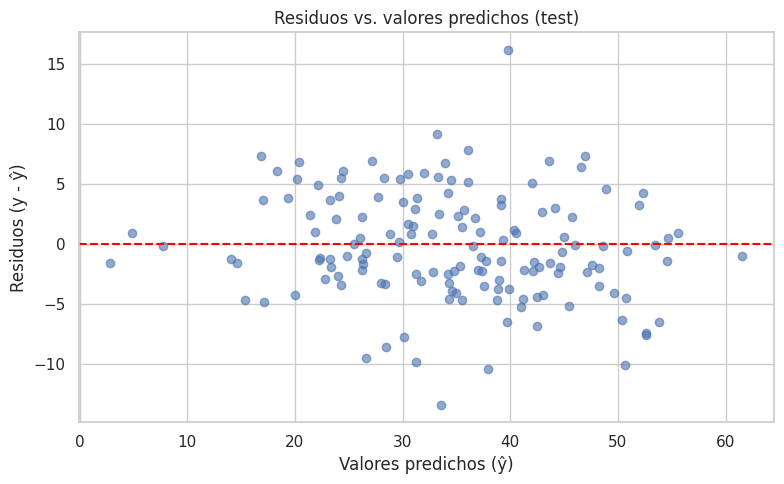

In [21]:
# Residuos sobre el conjunto de test del modelo ganador
residuos = y_test_H2 - y_pred_test_H2

plt.figure(figsize=(8, 5))
plt.scatter(y_pred_test_H2, residuos, alpha=0.6)
plt.axhline(y=0, color='red', linestyle='--')
plt.xlabel("Valores predichos (ŷ)")
plt.ylabel("Residuos (y - ŷ)")
plt.title("Residuos vs. valores predichos (test)")
plt.tight_layout()
plt.show()

En cuanto a la distribución de los residuos sobre el conjunto de test del modelo H2, se observa una **distribución homogénea** alrededor de cero: la nube se reparte de forma simétrica por encima y por debajo de la línea 0, con una amplitud aproximadamente **constante** a lo largo de todo el rango de valores predichos. Esto indica dos cosas:

- **Ausencia de sesgo sistemático:** al estar los residuos centrados en 0 en todo el rango, el modelo no sobreestima ni infraestima de forma sistemática en ninguna zona.
- **Homocedasticidad (varianza constante del error):** la dispersión no crece ni se estrecha con los valores predichos, por lo que el modelo es igual de fiable en todo el rango de `dropout_risk_score`.

Este resultado **valida los supuestos de la regresión lineal** y confirma que no era necesaria ninguna transformación de variables para corregir problemas de varianza. Conviene matizar el papel de la homocedasticidad: OLS proporciona coeficientes **insesgados aunque no se cumpla**; lo que su cumplimiento garantiza es que los **errores estándar y, por tanto, la inferencia** (p-valores, intervalos de confianza) sean válidos, y que el estimador sea el más eficiente (OLS es BLUE bajo estas condiciones). Por tanto, la homocedasticidad observada refuerza la validez del modelo lineal elegido.

En conclusión, el modelo H2 puede utilizarse para predecir el riesgo de abandono de forma fiable en todo el rango, siempre teniendo presente el error asociado (RMSE ≈ 4.5 puntos sobre la escala del target).

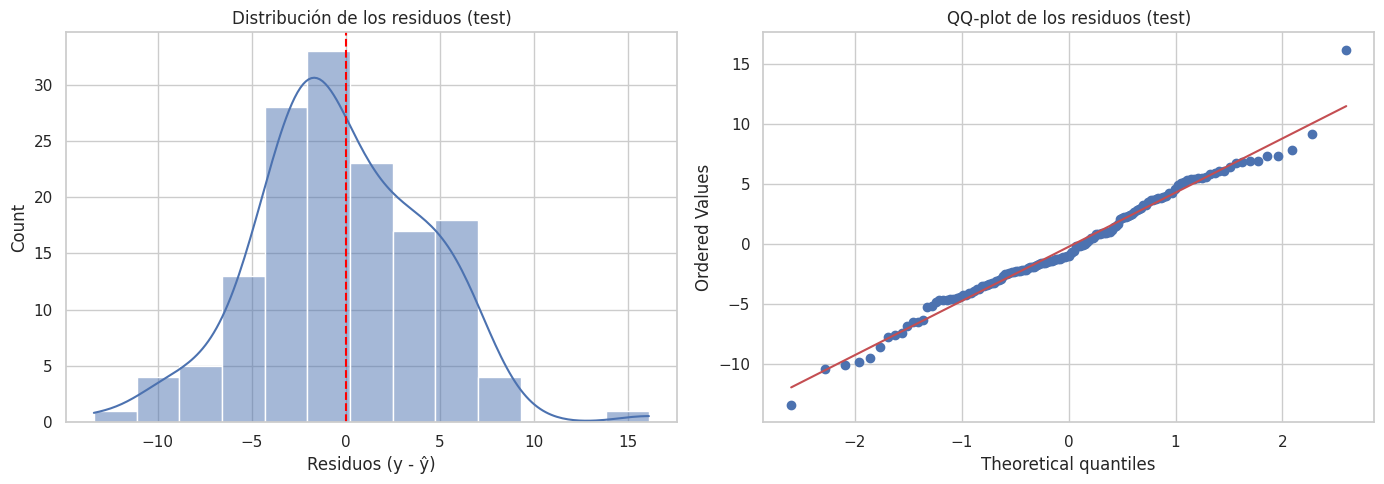

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histograma de residuos
sns.histplot(residuos, kde=True, ax=axes[0])
axes[0].axvline(x=0, color='red', linestyle='--')
axes[0].set_xlabel("Residuos (y - ŷ)")
axes[0].set_title("Distribución de los residuos (test)")

# QQ-plot
stats.probplot(residuos, dist="norm", plot=axes[1])
axes[1].set_title("QQ-plot de los residuos (test)")

plt.tight_layout()
plt.show()

El análisis de normalidad de los residuos (histograma y QQ-plot) muestra una distribución aproximadamente normal: el histograma presenta forma de campana centrada en 0 y, en el QQ-plot, los puntos siguen la diagonal teórica en todo el cuerpo central de la distribución. Solo se observan desviaciones leves en las colas (una cola izquierda ligeramente más pesada y un residuo atípico positivo de ~+16), habituales en una muestra de este tamaño y que no comprometen el supuesto.

Con la homocedasticidad verificada en el gráfico anterior y la normalidad confirmada aquí, se cumplen los supuestos clave de la regresión lineal. Por tanto, el modelo H2 es válido y su inferencia (coeficientes, errores estándar y p-valores) puede considerarse fiable.

###### Inferencia de ejemplo

In [23]:
input_inferencia=x_test_H2.iloc[[50]]
prediction_real_inferencia=y_test_H2.iloc[[50]]
inferencia_prediction_input_inferencia=modelo_rl_H2.predict(input_inferencia)[0]
print(f"El modelo ha predicho: {inferencia_prediction_input_inferencia}, y el valor real es {prediction_real_inferencia.to_string(index=False)}\n")
error_inferencia= inferencia_prediction_input_inferencia - prediction_real_inferencia
print(f"El modelo ha demostrado un error en esta inferencia de: {error_inferencia.to_string(index=False)} unidades de riesgo de abandono")

El modelo ha predicho: 14.028121098268691, y el valor real es 12.786873

El modelo ha demostrado un error en esta inferencia de: 1.241248 unidades de riesgo de abandono
